# COMP813 — Cross-Dataset Generalisation of NLP Models for Phishing Email Detection

## Model 1: TF-IDF + Logistic Regression

### Objective

This notebook establishes a traditional machine-learning baseline
for phishing/spam email detection using the Enron email dataset.

The model uses TF-IDF representations of email subject and body text
and Logistic Regression for binary classification.

### Experimental Design

- Training data: Enron training split
- Validation data: Enron validation split
- Test data: Enron test split
- External evaluation: CEAS-08 (performed separately)

### Input

Email subject + email body

### Target

- 0 = Legitimate
- 1 = Phishing/Spam

### Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

## 1. Load Dataset

The cleaned Enron dataset was divided into training, validation,
and test sets using stratified sampling.

The same fixed splits are used across all COMP813 models to ensure
a fair comparison between approaches.

In [4]:
train_df = pd.read_csv("enron_train.csv")
val_df = pd.read_csv("enron_val.csv")
test_df = pd.read_csv("enron_test.csv")

print("Training set:", train_df.shape)
print("Validation set:", val_df.shape)
print("Test set:", test_df.shape)

Training set: (20596, 2)
Validation set: (4414, 2)
Test set: (4414, 2)


## 2. Dataset Overview

In [5]:
print("Training set label distribution:")
print(train_df["label"].value_counts())
print()

print("Validation set label distribution:")
print(val_df["label"].value_counts())
print()

print("Test set label distribution:")
print(test_df["label"].value_counts())

Training set label distribution:
label
0    10831
1     9765
Name: count, dtype: int64

Validation set label distribution:
label
0    2321
1    2093
Name: count, dtype: int64

Test set label distribution:
label
0    2322
1    2092
Name: count, dtype: int64


In [6]:
train_df.head()

,text,label
0,subject: fw : cancel pedricktown visit body: a...,0
1,subject: fortune body: here ' s the fortune li...,0
2,subject: re : org charts body: i have received...,0
3,subject: stoop it deaaaaad in it ' s tracks bo...,1
4,subject: greatly improve your stamina body: my...,1


## 3. Prepare Features and Target

The model uses only the combined email text consisting of the
subject and body.

Metadata such as sender, receiver, date, and URL counts are not
used because the objective is to evaluate text-based NLP
generalisation across datasets.

In [7]:
X_train = train_df["text"]
y_train = train_df["label"]

X_val = val_df["text"]
y_val = val_df["label"]

X_test = test_df["text"]
y_test = test_df["label"]

## 4. TF-IDF Feature Extraction

Term Frequency–Inverse Document Frequency (TF-IDF) is used to
represent each email as a numerical feature vector.

The vectorizer is fitted exclusively on the training data.
The validation and test sets are transformed using the fitted
vectorizer without refitting.

This prevents information leakage from the evaluation sets.

In [8]:
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=100000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Test matrix:", X_test_tfidf.shape)

Training matrix: (20596, 100000)
Validation matrix: (4414, 100000)
Test matrix: (4414, 100000)


## 5. Logistic Regression Model

Logistic Regression is used as the first baseline classifier.

The `balanced` class weighting is retained to account for the
slight difference between the legitimate and phishing/spam classes.

In [9]:
start_time = time.time()

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

training_time = time.time() - start_time

print(f"Training time: {training_time:.2f} seconds")

Training time: 0.94 seconds


## 6. Validation Evaluation

In [10]:
lr_val_pred = lr_model.predict(X_val_tfidf)

print(classification_report(
    y_val,
    lr_val_pred,
    target_names=["Legitimate", "Phishing/Spam"]
))

               precision    recall  f1-score   support

   Legitimate       1.00      0.97      0.99      2321
Phishing/Spam       0.97      1.00      0.98      2093

     accuracy                           0.99      4414
    macro avg       0.99      0.99      0.99      4414
 weighted avg       0.99      0.99      0.99      4414



In [11]:
val_accuracy = accuracy_score(y_val, lr_val_pred)
val_precision = precision_score(y_val, lr_val_pred)
val_recall = recall_score(y_val, lr_val_pred)
val_f1 = f1_score(y_val, lr_val_pred)

print(f"Accuracy : {val_accuracy:.4f}")
print(f"Precision: {val_precision:.4f}")
print(f"Recall   : {val_recall:.4f}")
print(f"F1 Score : {val_f1:.4f}")

Accuracy : 0.9855
Precision: 0.9725
Recall   : 0.9976
F1 Score : 0.9849


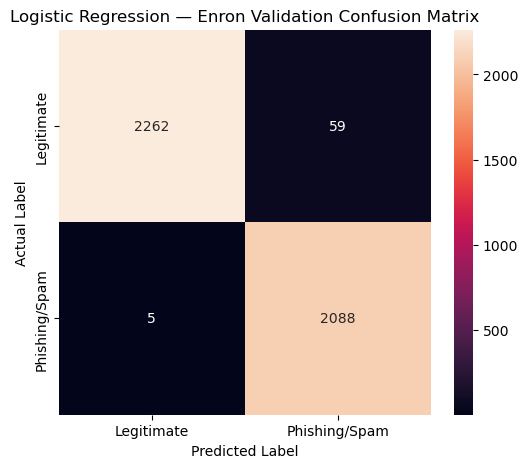

In [12]:
cm_val = confusion_matrix(y_val, lr_val_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_val,
    annot=True,
    fmt="d",
    xticklabels=["Legitimate", "Phishing/Spam"],
    yticklabels=["Legitimate", "Phishing/Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression — Enron Validation Confusion Matrix")

plt.show()

## 7. Final Enron Test Evaluation

The test set is evaluated only after the model has been trained
and the validation results have been obtained.

In [13]:
lr_test_pred = lr_model.predict(X_test_tfidf)

print(classification_report(
    y_test,
    lr_test_pred,
    target_names=["Legitimate", "Phishing/Spam"]
))

               precision    recall  f1-score   support

   Legitimate       1.00      0.98      0.99      2322
Phishing/Spam       0.97      1.00      0.98      2092

     accuracy                           0.99      4414
    macro avg       0.99      0.99      0.99      4414
 weighted avg       0.99      0.99      0.99      4414



In [14]:
test_accuracy = accuracy_score(y_test, lr_test_pred)
test_precision = precision_score(y_test, lr_test_pred)
test_recall = recall_score(y_test, lr_test_pred)
test_f1 = f1_score(y_test, lr_test_pred)

print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1 Score : {test_f1:.4f}")

Accuracy : 0.9855
Precision: 0.9743
Recall   : 0.9957
F1 Score : 0.9849


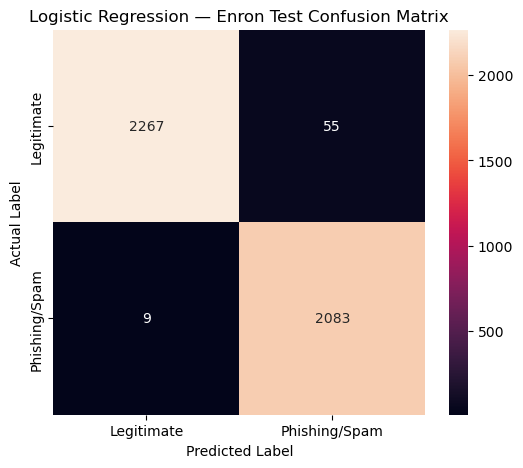

In [15]:
cm_test = confusion_matrix(y_test, lr_test_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    xticklabels=["Legitimate", "Phishing/Spam"],
    yticklabels=["Legitimate", "Phishing/Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression — Enron Test Confusion Matrix")

plt.show()

## 8. Results Summary

In [16]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Validation": [
        val_accuracy,
        val_precision,
        val_recall,
        val_f1
    ],
    "Test": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

results

,Metric,Validation,Test
0,Accuracy,0.985501,0.985501
1,Precision,0.972520,0.974275
2,Recall,0.997611,0.995698
3,F1 Score,0.984906,0.984870


## 9. Observations

The TF-IDF + Logistic Regression baseline achieved strong performance
on the held-out Enron test set, with an F1-score of approximately
98.49%.

The model achieved high recall for the phishing/spam class, indicating
that relatively few phishing/spam emails were incorrectly classified
as legitimate.

The validation and test results were very similar, suggesting
consistent performance across the two held-out Enron subsets.

These results establish the baseline against which the subsequent
SVM and BiLSTM models will be compared.

Importantly, these results represent in-domain performance only.
The model's ability to generalise to the unseen CEAS-08 dataset will
be evaluated separately.

In [18]:
import os
import joblib

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save model and vectorizer
joblib.dump(
    lr_model,
    "../models/logistic_regression_enron.pkl"
)

joblib.dump(
    tfidf,
    "../models/tfidf_vectorizer.pkl"
)

print("Model and TF-IDF vectorizer saved successfully.")

Model and TF-IDF vectorizer saved successfully.
